# 09 - Projecting the 2026 rookie class

The frozen system, applied to this season's rookies.

- **Final model:** same specification as tested (the ensemble and its settings),
  now trained on **every class with a known outcome** (2000-2022). This is the
  standard step after evaluation: the recipe doesn't change, it just gets more
  data, including the recent era the test showed it was missing.
- **Window:** the rookies have played only ~15 team games so far. A model built on
  25-game features shouldn't be fed 15-game features, so until mid-December the
  projections use the **15-game version** (built and validated in 06: about 70% of
  the 25-game gain). Change `WINDOW` below to 25 once they get there.
- **Warning:** only "heavy minutes, weak team", the profile that held on the test.

**Refresh:** `python src/fetch_current_season.py`, then
`python src/build_current_features.py --window 15` (or 25), then re-run this notebook.

Remember what the test showed: projections for recent classes run a bit
optimistic (the league spreads minutes more than it used to), and 25 games
can't separate an All-Star from a superstar.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
import projection as pj
from build_rookie_window import window_suffix
from plot_style import apply_style, BLUE, ORANGE, NEUTRAL, INK_2, SEQ_BLUE

apply_style()

WINDOW = 15  # switch to 25 when the rookies reach 25 team games (mid-December)

train = md.add_pick_terms(m.load_table("model_table" + window_suffix(WINDOW)))
current = md.add_pick_terms(pd.read_csv(ROOT / "data" / "processed" / f"current_features{window_suffix(WINDOW)}.csv"))
as_of = current["as_of"].iloc[0]
print(f"Training: {len(train)} players, classes {train['draft_year'].min()}-{train['draft_year'].max()}, "
      f"{WINDOW}-game features")
print(f"Current rookies who have debuted: {len(current)} (data as of {as_of})")
print(f"Their windows so far: {int(current['window_team_games'].min())}-{int(current['window_team_games'].max())} team games")
too_old = current[current["age_at_debut"] > 25]
if len(too_old):
    print(f"Outside the model's scope (debuted older than 25): {', '.join(too_old['player_name'])}")

Training: 1180 players, classes 2000-2022, 15-game features
Current rookies who have debuted: 46 (data as of 2026-11-19)
Their windows so far: 5-15 team games


In [2]:
# Final models: trained on every class with a known outcome
final = md.ensemble().fit(train[md.ALL], train[m.TARGET])
quantile_models = {q: md.boosting(loss="quantile", quantile=q).fit(train[md.ALL], train[m.TARGET])
                   for q in [0.1, 0.5, 0.9]}
base = md.baseline().fit(train[["pick"]], train[m.TARGET])

current["model_pred"] = final.predict(current[md.ALL])
current["base_pred"] = base.predict(current[["pick"]])
qs = np.sort(np.column_stack([quantile_models[q].predict(current[md.ALL]) for q in [0.1, 0.5, 0.9]]), axis=1)
current[["p10", "p50", "p90"]] = qs

# Reference for probabilities and the warning: out-of-fold predictions on the training classes
_, train_oof = m.repeated_cv(md.ensemble, md.ALL, train)
cur = current.set_index("player_id")
probs = pj.tier_probabilities(cur["model_pred"], train_oof, train[m.TARGET],
                              bandwidth=0.5, min_neighbors=50)
history = pj.profile_history(train, train_oof)
cur = cur.join(probs)
cur["p_starter_plus"] = cur["Starter"] + cur["All-Star level"]
cur["warning"] = pj.minutes_profile(cur).isin(pj.SHOWN_PROFILES)
print("Done")

Done


## 1. The class at a glance

In [3]:
board = cur[cur["age_at_debut"] <= 25].sort_values("model_pred", ascending=False)
cols = ["player_name", "pick", "debut_team", "age_at_debut", "games_played", "window_team_games", "mpg",
        "base_pred", "model_pred", "p10", "p90", "p_starter_plus", "All-Star level", "warning"]
show = board[cols].rename(columns={"base_pred": "pick expects", "model_pred": "model",
                                   "p_starter_plus": "P(starter+) %", "All-Star level": "P(All-Star) %"})
show[["P(starter+) %", "P(All-Star) %"]] = (100 * show[["P(starter+) %", "P(All-Star) %"]]).round(0)
show.head(25).round(1).reset_index(drop=True)

,player_name,pick,debut_team,age_at_debut,games_played,window_team_games,mpg,pick expects,model,p10,p90,P(starter+) %,P(All-Star) %,warning
0,Cameron Boozer,3,MEM,19,15,15.0,31.0,2.9,6.1,-0.3,9.7,56.0,40.0,False
1,Yaxel Lendeborg,11,GSW,24,15,15.0,30.7,1.4,4.9,-0.0,7.7,48.0,38.0,False
2,Darius Acuff Jr.,7,SAC,20,13,13.0,36.8,1.9,4.7,-0.8,7.2,48.0,38.0,True
3,Darryn Peterson,2,UTA,20,15,15.0,31.3,3.5,4.2,-0.3,8.1,46.0,30.0,True
4,AJ Dybantsa,1,WAS,20,12,12.0,32.7,4.6,4.0,-0.4,6.9,42.0,24.0,True
5,Keaton Wagler,5,LAC,19,13,13.0,22.8,2.3,3.9,-0.2,7.9,42.0,24.0,False
6,Caleb Wilson,4,CHI,20,10,14.0,30.7,2.5,3.0,-0.0,5.9,28.0,12.0,True
7,Kingston Flemings,8,ATL,20,12,15.0,21.5,1.7,2.8,-0.3,5.2,26.0,10.0,False
8,Meleek Thomas,34,CLE,20,13,14.0,23.8,0.6,2.6,-0.1,4.6,23.0,8.0,False
9,Brayden Burries,10,MIL,21,15,15.0,22.1,1.5,2.2,0.0,5.2,16.0,5.0,False


**How to read it:** "pick expects" is what the draft slot alone predicts; "model"
adds the first games. The gap between them is the story: players well above their
pick are outplaying their draft slot early. P10-P90 is the floor-to-ceiling range.

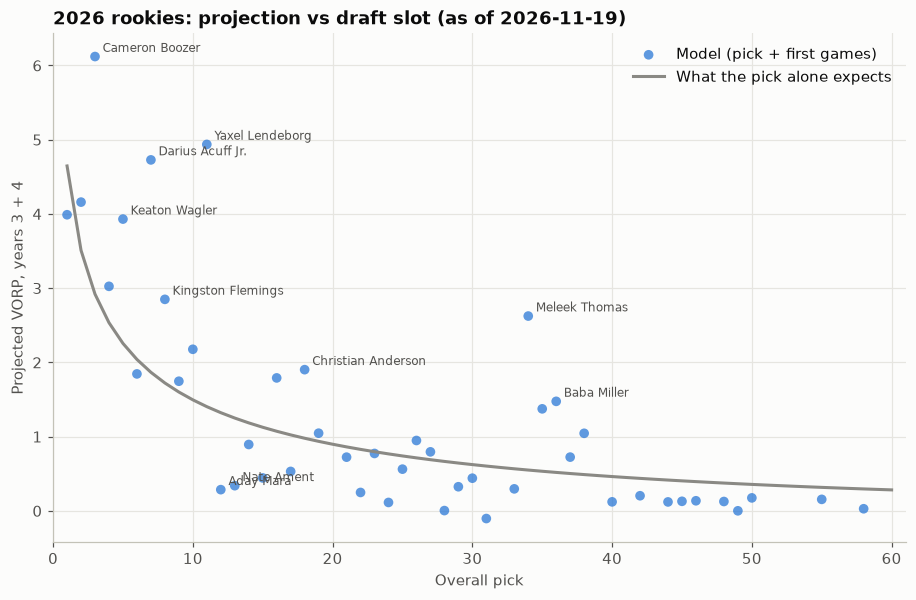

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
b = board.dropna(subset=["model_pred"])
ax.scatter(b["pick"], b["model_pred"], s=40, color=BLUE, alpha=0.75, edgecolor="none", label="Model (pick + first games)")
grid = pd.DataFrame({"pick": np.arange(1, 61)})
ax.plot(grid["pick"], base.predict(grid[["pick"]]), color=NEUTRAL, label="What the pick alone expects")
gap = (b["model_pred"] - b["base_pred"])
for _, r in b.loc[gap.abs().sort_values(ascending=False).index[:10]].iterrows():
    ax.annotate(r["player_name"], (r["pick"], r["model_pred"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title=f"2026 rookies: projection vs draft slot (as of {as_of})", xlabel="Overall pick",
       ylabel="Projected VORP, years 3 + 4", xlim=(0, 61))
ax.legend(loc="upper right")
plt.show()

**What to look for:** dots well above the grey line are early overperformers for
their slot; dots well below are top picks whose first games haven't matched the
draft position yet. The 10 biggest gaps are labelled.

## 2. Player cards

In [5]:
def card(name):
    rows = cur[cur["player_name"] == name]
    if rows.empty:
        print(f"{name}: no NBA games yet (or not in the 2026 draft class)\n")
        return
    r = rows.iloc[0]
    comps = pj.style_comps(rows.reset_index(), train, k=3)
    warning = pj.profile_warning(pj.minutes_profile(rows).iloc[0], history, shown=pj.SHOWN_PROFILES)
    lines = [
        f"{name} - #{int(r['pick'])} pick, {r['debut_team']}, age {int(r['age_at_debut'])} on Feb 1",
        f"  So far: {r['mpg']:.1f} mpg in {int(r['games_played'])} of {int(r['window_team_games'])} team games",
        f"  Pick alone expects: {r['base_pred']:.1f} VORP (years 3+4) | model central case: {r['model_pred']:.1f}",
        f"  Floor (p10) {r['p10']:.1f} | median (p50) {r['p50']:.1f} | ceiling (p90) {r['p90']:.1f}",
        "  Tier probabilities: " + " | ".join(f"{t} {r[t]:.0%}" for t in pj.TIER_NAMES)
        + f"  (based on ~{r['n_eff']:.0f} similar players)",
        "  Looks like: " + ", ".join(f"{a} (#{b}, {c})" for a, b, c in
                                      zip(comps["comp"], comps["comp_pick"], comps["comp_draft_year"])),
    ]
    if warning:
        lines.append("  " + warning)
    if r["age_at_debut"] > 25:
        lines.append("  Note: debuted older than 25, outside the population the model was built for")
    print("\n".join(lines) + "\n")


NAMED = ["Yaxel Lendeborg", "Darius Acuff Jr.", "AJ Dybantsa", "Darryn Peterson", "Cameron Boozer"]
for name in NAMED:
    card(name)

Yaxel Lendeborg - #11 pick, GSW, age 24 on Feb 1
  So far: 30.7 mpg in 15 of 15 team games
  Pick alone expects: 1.4 VORP (years 3+4) | model central case: 4.9
  Floor (p10) -0.0 | median (p50) 3.7 | ceiling (p90) 7.7
  Tier probabilities: Little or no value 22% | Bench 12% | Rotation 18% | Starter 10% | All-Star level 38%  (based on ~50 similar players)
  Looks like: Drew Gooden (#4, 2002), Channing Frye (#8, 2005), MarShon Brooks (#25, 2011)

Darius Acuff Jr. - #7 pick, SAC, age 20 on Feb 1
  So far: 36.8 mpg in 13 of 13 team games
  Pick alone expects: 1.9 VORP (years 3+4) | model central case: 4.7
  Floor (p10) -0.8 | median (p50) 3.4 | ceiling (p90) 7.2
  Tier probabilities: Little or no value 22% | Bench 12% | Rotation 18% | Starter 10% | All-Star level 38%  (based on ~51 similar players)
  Looks like: Brandon Jennings (#10, 2009), Dennis Smith Jr. (#9, 2017), Trae Young (#5, 2018)
  Warning - heavy minutes, weak team: historically the model was too optimistic for this profile by

In [6]:
print("Top 5 by projection (not already shown):\n")
for name in board["player_name"].head(10):
    if name not in NAMED:
        card(name)

Top 5 by projection (not already shown):

Keaton Wagler - #5 pick, LAC, age 19 on Feb 1
  So far: 22.8 mpg in 13 of 13 team games
  Pick alone expects: 2.3 VORP (years 3+4) | model central case: 3.9
  Floor (p10) -0.2 | median (p50) 2.2 | ceiling (p90) 7.9
  Tier probabilities: Little or no value 25% | Bench 13% | Rotation 20% | Starter 18% | All-Star level 24%  (based on ~61 similar players)
  Looks like: George Hill (#26, 2008), Isaiah Thomas (#60, 2011), Keyon Dooling (#10, 2000)

Caleb Wilson - #4 pick, CHI, age 20 on Feb 1
  So far: 30.7 mpg in 10 of 14 team games
  Pick alone expects: 2.5 VORP (years 3+4) | model central case: 3.0
  Floor (p10) -0.0 | median (p50) 2.1 | ceiling (p90) 5.9
  Tier probabilities: Little or no value 26% | Bench 20% | Rotation 25% | Starter 17% | All-Star level 12%  (based on ~110 similar players)
  Looks like: Kevin Durant (#2, 2007), Michael Beasley (#2, 2008), Carmelo Anthony (#3, 2003)
  Warning - heavy minutes, weak team: historically the model wa

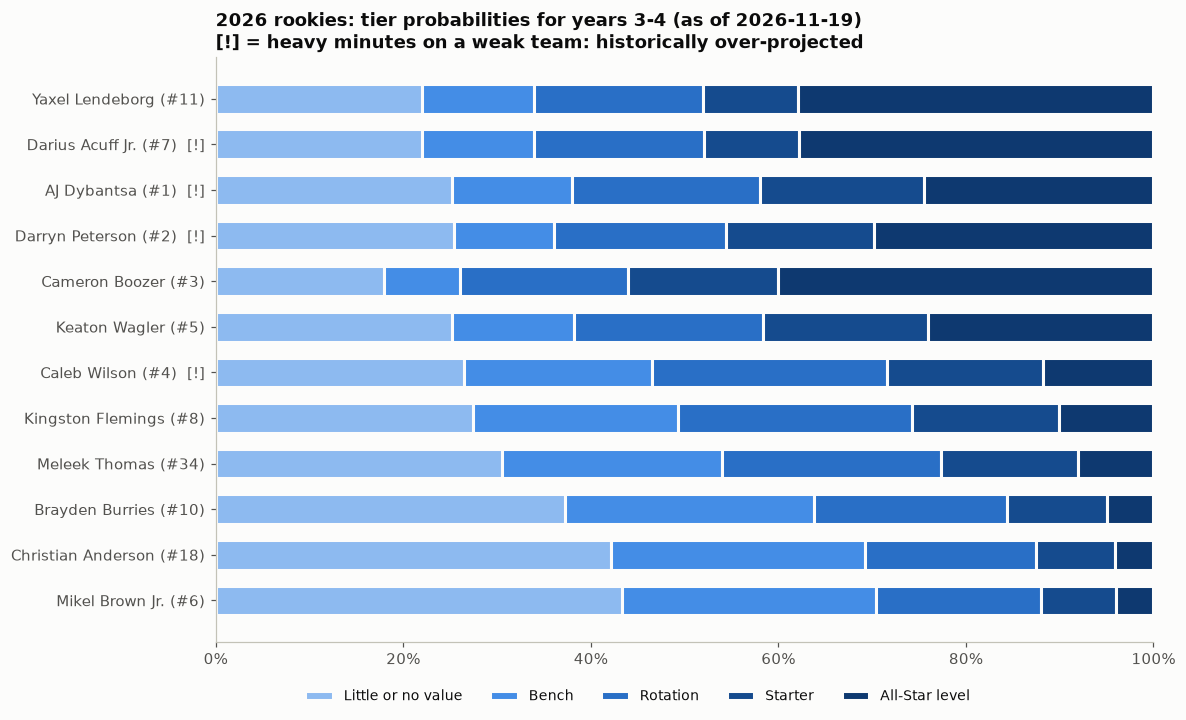

In [7]:
SHOW = list(dict.fromkeys([n for n in NAMED if n in set(cur["player_name"])]
                          + board["player_name"].head(12).tolist()))
sel = cur.reset_index().set_index("player_name").loc[SHOW]
colors = [to_hex(SEQ_BLUE(v)) for v in np.linspace(0.18, 0.95, len(pj.TIER_NAMES))]

fig, ax = plt.subplots(figsize=(11, 0.45 * len(sel) + 1.5))
left = np.zeros(len(sel))
for t, color in zip(pj.TIER_NAMES, colors):
    vals = sel[t].to_numpy()
    ax.barh(range(len(sel)), vals, left=left, color=color, height=0.65,
            edgecolor="#fcfcfb", linewidth=2, label=t)
    left += vals
ax.set_yticks(range(len(sel)), [f"{n} (#{int(r['pick'])})" + ("  [!]" if r["warning"] else "")
                                for n, r in sel.iterrows()])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.06), fontsize=9)
ax.set_title(f"2026 rookies: tier probabilities for years 3-4 (as of {as_of})\n"
             "[!] = heavy minutes on a weak team: historically over-projected")
plt.show()

**Reminder:** with only ~15 games, these probabilities rest on less evidence than
the 25-game version validated in 08. They should sharpen in December.